# Step 1. Can we train detectors that find where the answers are?

**The question.** The product receives a scanned exam and must hand the grading agent a list of answers, each
under its question number. Before anything can be read, it has to know *where* the answers are. The first idea,
the same recipe as Assignment 2's seal detector, is to fine-tune two YOLO detectors on public data:

| Detector | What it finds | Trained on (Roboflow Universe, used as published) | Licence |
|---|---|---|---|
| `question_no` | the handwritten question number at the start of each answer | `answersheet/answer-sheet-component-detection` v1 | CC BY 4.0 |
| `text_line` | each handwritten line, so a text recogniser (TrOCR) can read it | `nucularvision/handwritten-text-line-dataset` v1 | CC BY 4.0 |

Nothing from the Mendeley exams is used here: those 50 exams are the final evaluation of the whole product (step 7).

**How this chapter reads**, top to bottom like Assignment 2's `train.py`:

    Part 1  The data              download, look at it, describe it
    Part 2  Cleaning              what is wrong in the labels and how each problem is fixed
    Part 3  Why this split        the leakage evidence, then a split by booklet and by photo session
    Part 4  YOLO datasets         one dataset per detector, labels drawn back on to check them
    Part 5  Baselines             simple rules and COCO YOLO zero-shot: is training needed at all?
    Part 6  Fine-tuning grid      a small planned grid, chosen on validation only
    Part 7  Save and threshold    the chosen weights, and precision and recall at several thresholds
    Part 8  Test, once            the chosen models and the baselines on the test split

Run it with `uv run --group train python -m vision.step1_detectors` (or open `vision/notebooks/step1_detectors.ipynb`
to read it with its outputs). The full grid takes 4 to 7 hours on a laptop, so the finished runs are kept in
`~/.cache/daiist-vision/runs/` and a second run evaluates them again instead of retraining. Switches:

    RETRAIN=1   train every grid run again, even if it already finished
    SMOKE=1     one tiny run per detector on CPU, to check the code end to end (the numbers mean nothing)
    DEVICE=cpu  force a device (default: mps on an Apple laptop, cuda with an NVIDIA GPU, else cpu)

In [1]:
# The chapter runs both as a script and as a notebook, so the repository root is found from the working folder
# (a notebook has no __file__), and added to the import path.
import json
import os
import shutil
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "vision" / "reader.py").is_file())
sys.path.insert(0, str(ROOT))
os.environ.setdefault("YOLO_VERBOSE", "False")  # Ultralytics' progress bars would bury the tables

import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import yaml  # noqa: E402

import env  # noqa: E402
from vision import datasets, eda  # noqa: E402

env.load_env()  # ROBOFLOW_API_KEY, only needed for the first download
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

OUT = datasets.ARTIFACTS / "step1_detectors"   # every table and figure of this chapter
WEIGHTS = ROOT / "weights"
RUNS = datasets.WORK / "runs"                  # outside the repo (see vision/datasets.py)
BUILT = datasets.WORK / "built"

SMOKE = os.environ.get("SMOKE") == "1"
RETRAIN = os.environ.get("RETRAIN") == "1"
SEED = 0
EPOCHS, PATIENCE = (1, 1) if SMOKE else (40, 10)
IMGSZ = 320 if SMOKE else 640
# A smoke run writes its baselines, grid and weights to the work folder, never to the repo, so a test run cannot
# be committed by mistake; its runs get their own folder so a 1-epoch run is never reused as a real one.
RESULTS = datasets.WORK / "smoke" if SMOKE else OUT
if SMOKE:
    WEIGHTS = datasets.WORK / "smoke"
    RUNS = datasets.WORK / "smoke" / "runs"
for folder in (OUT, RESULTS, WEIGHTS, RUNS):
    folder.mkdir(parents=True, exist_ok=True)


def pick_device() -> str:
    if os.environ.get("DEVICE"):
        return os.environ["DEVICE"]
    import torch
    if torch.cuda.is_available():
        return "0"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


DEVICE = "cpu" if SMOKE else pick_device()
print(f"Training device: {DEVICE}")
# Ultralytics downloads yolo11n.pt and yolo11s.pt into the working folder: keep them out of the repo.
os.chdir(datasets.WORK)

Training device: mps


## Part 1. The data

Both datasets are downloaded at a pinned version, exactly as their authors published them. Roboflow exports
every source photo several times (augmented copies, and for the lines set 2x2 tiles), so each image is mapped
back to its **source photo** (the part of the file name before `.rf.`) and to its **group**: the student's
booklet for the answer sheets, the photo session for the lines. Those two columns matter for the split in Part 3.

In [2]:
folders = {name: datasets.download(name) for name in datasets.SOURCES}
index = pd.concat([datasets.index_images(n, f) for n, f in folders.items()], ignore_index=True)
class_names = {name: yaml.safe_load((folder / "data.yaml").read_text())["names"] for name, folder in folders.items()}
print("classes in each export:", class_names)

describe = (index.groupby(["dataset", "roboflow_split"])
            .agg(images=("file", "size"), source_photos=("source", "nunique"), groups=("group", "nunique"),
                 images_without_boxes=("n_boxes", lambda s: int((s == 0).sum())), boxes=("n_boxes", "sum"))
            .reset_index())
eda.show(describe, "Images, source photos, groups and boxes per Roboflow split:")
describe.to_csv(OUT / "dataset_summary.csv", index=False)

copies = (index.groupby(["dataset", "source"]).size().rename("copies").reset_index()
          .groupby(["dataset", "copies"]).size().rename("photos").reset_index())
eda.show(copies, "How many exported images each source photo became:")

classes in each export: {'answersheet': ['equation', 'figure', 'heading', 'paragraph', 'question_no', 'table'], 'lines': ['handwritten text detection - v1 2023-03-31 6-36pm']}

Images, source photos, groups and boxes per Roboflow split:


,dataset,roboflow_split,images,source_photos,groups,images_without_boxes,boxes
0,answersheet,train,576,192,8,0,2385
1,lines,test,52,13,12,6,211
2,lines,train,1116,93,79,89,3778
3,lines,valid,112,28,24,8,491



How many exported images each source photo became:


,dataset,copies,photos
0,answersheet,3,192
1,lines,4,41
2,lines,12,93


Two things stand out already. The answer-sheet set puts **everything in train** (576 images from 192 photos of
8 booklets), so we have to make our own validation and test splits. And every source photo became 3 images
(answer sheets) or 4 to 12 (lines: 4 tiles, some of them augmented 3 times), so a split by image would put
copies of one page on both sides.

In [3]:
sizes = pd.concat([eda.image_sizes(part["path"]).assign(dataset=name) for name, part in index.groupby("dataset")])
eda.show(sizes.groupby("dataset")[["width", "height"]].agg(["min", "max"]), "Image width and height in pixels:")


Image width and height in pixels:


width      height     
              min  max    min  max
dataset                           
answersheet   640  640    640  640
lines         640  640    640  640

In [4]:


def label_rows(index: pd.DataFrame) -> pd.DataFrame:
    """One row per label line: its class, whether it is a box (4 numbers) or a polygon (more), and the size of
    its enclosing box as a fraction of the image."""
    rows = []
    for r in index.itertuples():
        label = Path(r.label)
        if not label.is_file():
            rows.append(dict(dataset=r.dataset, roboflow_split=r.roboflow_split, file=r.file, source=r.source,
                             cls=None, shape="no label file", w=np.nan, h=np.nan))
            continue
        for line in label.read_text().splitlines():
            parts = line.split()
            if not parts:
                continue
            coords = list(map(float, parts[1:]))
            if len(coords) > 4:
                xs, ys = coords[0::2], coords[1::2]
                w, h, shape = max(xs) - min(xs), max(ys) - min(ys), "polygon"
            else:
                w, h, shape = coords[2], coords[3], "box"
            rows.append(dict(dataset=r.dataset, roboflow_split=r.roboflow_split, file=r.file, source=r.source,
                             cls=class_names[r.dataset][int(parts[0])], shape=shape, w=w, h=h))
    return pd.DataFrame(rows)


labels = label_rows(index)
eda.show(labels.groupby(["dataset", "cls"]).size().rename("labels").reset_index(),
         "Labels per class (the answer-sheet export has six classes; we need only question_no):")
eda.show(labels.groupby(["dataset", "shape"]).size().rename("rows").reset_index(), "Label shapes:")


Labels per class (the answer-sheet export has six classes; we need only question_no):


,dataset,cls,labels
0,answersheet,equation,366
1,answersheet,figure,117
2,answersheet,heading,84
3,answersheet,paragraph,1005
4,answersheet,question_no,777
5,answersheet,table,36
6,lines,handwritten text detection - v1 2023-03-31 6-36pm,4480



Label shapes:


,dataset,shape,rows
0,answersheet,box,2385
1,lines,box,4222
2,lines,polygon,258



Objects per image:


,question numbers per answer-sheet image,lines per lines image
count,576.000,1280.0
missing,0.000,0.0
min,0.000,0.0
median,1.000,3.0
mean,1.349,3.5
max,7.000,19.0


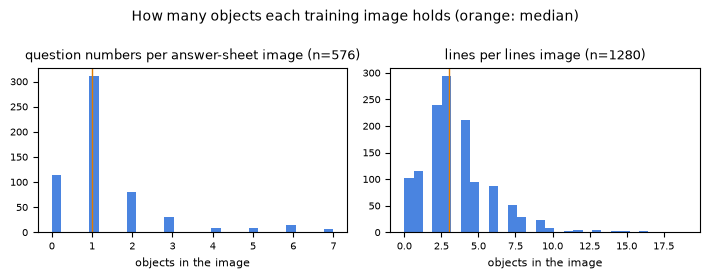

figure: eda_objects_per_image.png


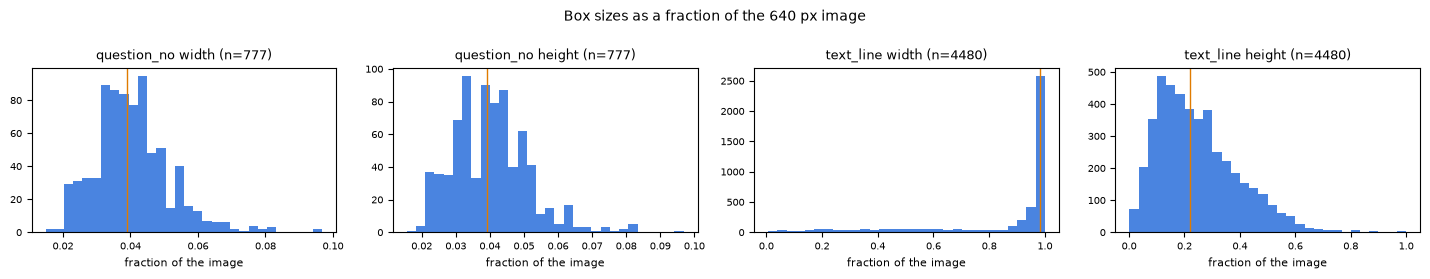

figure: eda_box_sizes.png


In [5]:
question_no = labels[(labels["dataset"] == "answersheet") & (labels["cls"] == "question_no")]
text_line = labels[labels["dataset"] == "lines"]
per_image = {
    "question numbers per answer-sheet image":
        index[index["dataset"] == "answersheet"]["file"].map(question_no.groupby("file").size()).fillna(0),
    "lines per lines image":
        index[index["dataset"] == "lines"]["file"].map(text_line.groupby("file").size()).fillna(0),
}
eda.show(pd.DataFrame({k: eda.describe(v) for k, v in per_image.items()}), "Objects per image:")
eda.histograms(per_image, "objects in the image", OUT / "eda_objects_per_image.png",
               "How many objects each training image holds (orange: median)")
eda.histograms({"question_no width": question_no["w"], "question_no height": question_no["h"],
                "text_line width": text_line["w"], "text_line height": text_line["h"]},
               "fraction of the image", OUT / "eda_box_sizes.png", "Box sizes as a fraction of the 640 px image")

**What the EDA says.** Question numbers are small (a few percent of the page in each direction) and scarce:
777 labels over 576 images, which is 259 numbers on the 192 real pages, a median of 1 per image and at most 7.
Lines are wide and short, a median of 3 per tile. Small, scarce objects mean the question-number detector will be
the harder of the two, and every booklet held out for validation or test costs training examples.

## Part 2. Cleaning

Four problems were found by looking at the labels and the images, and each is fixed when the YOLO datasets are
built (`datasets.write_yolo`), not by editing the downloaded files:

1. **Six classes, one wanted.** The answer-sheet export also labels equations, figures, headings, paragraphs and
   tables. Only `question_no` is kept, renumbered to class 0.
2. **Polygons mixed with boxes.** Some WhatsApp photos in the lines set are labelled with polygons. Ultralytics
   drops any image whose label file mixes the two, so each polygon is replaced by its enclosing box.
3. **Augmented copies in validation and test.** Three exports of one answer-sheet page are the same page; in
   validation and test only the first copy is kept, so a page is not counted three times.
4. **Images without a box** stay in, as background: a tile of a notebook with no writing is a real case the line
   detector must learn to leave empty.

In [6]:
cleaning = pd.DataFrame([
    {"problem": "answer-sheet labels of other classes", "rows": int((labels["dataset"].eq("answersheet")
                                                                     & labels["cls"].ne("question_no")).sum()),
     "fix": "dropped"},
    {"problem": "polygon label rows (lines set)", "rows": int((labels["shape"] == "polygon").sum()),
     "fix": "replaced by their enclosing box"},
    {"problem": "images with no label file", "rows": int((labels["shape"] == "no label file").sum()),
     "fix": "kept as background"},
    {"problem": "lines images with no box", "rows": int((index["dataset"].eq("lines") & index["n_boxes"].eq(0)).sum()),
     "fix": "kept as background"},
])
eda.show(cleaning, "Problems found in the labels, and what is done about each:")


Problems found in the labels, and what is done about each:


,problem,rows,fix
0,answer-sheet labels of other classes,1608,dropped
1,polygon label rows (lines set),258,replaced by their enclosing box
2,images with no label file,0,kept as background
3,lines images with no box,103,kept as background


## Part 3. Why we split by booklet and by photo session, not by image

A detector that has seen a page in training will find its boxes again in validation, and the score would
flatter it. So before splitting we measure how alike images are: every image becomes a ResNet-18 feature
vector, and we compare pairs that are copies of the same photo, different photos of the same group, and
different groups. If same-group pairs look almost as alike as copies, the **group** is what must stay on one
side of the split.


Cosine similarity of image features, by type of pair (higher = more alike):


,dataset,pair,pairs,median,p95
0,answersheet,copy of the same photo,576,0.816,0.972
1,answersheet,"same group, different photo",22293,0.808,0.943
2,answersheet,different group,142731,0.769,0.896
3,lines,copy of the same photo,6384,0.848,0.944
4,lines,"same group, different photo",20496,0.785,0.901
5,lines,different group,791680,0.633,0.800


  answersheet: copies 0.816, same group 0.808, different groups 0.769 (medians), so the group, not the photo, must stay on one side of the split.
  lines: copies 0.848, same group 0.785, different groups 0.633 (medians), so the group, not the photo, must stay on one side of the split.


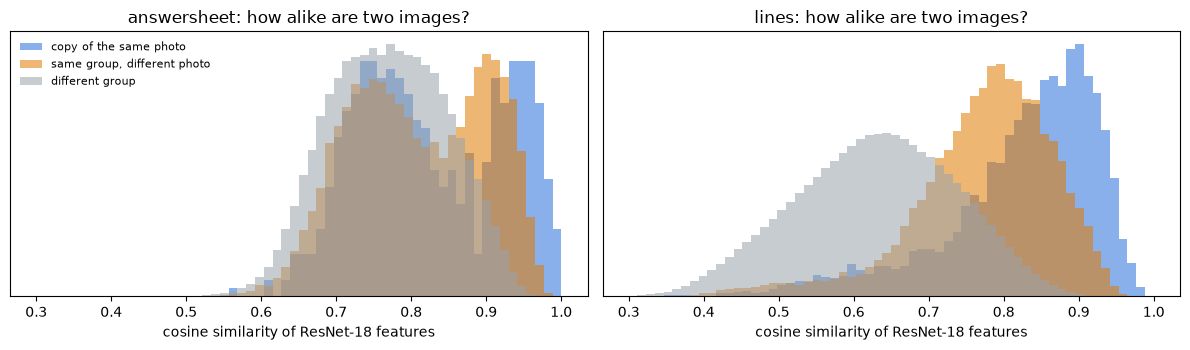

figure: similarity_by_pair_type.png


In [7]:
vectors = datasets.embed(index["path"].tolist(), datasets.WORK / "embeddings.npz")
summary, crossing = datasets.similarity_evidence(index, vectors)
eda.show(summary, "Cosine similarity of image features, by type of pair (higher = more alike):")
for name, part in summary.groupby("dataset", sort=False):
    med = part.set_index("pair")["median"]
    copy, group, other = med.get("copy of the same photo"), med.get("same group, different photo"), med.get("different group")
    verdict = ("so the group, not the photo, must stay on one side of the split"
               if group is not None and other is not None and group > other else "so groups add little beyond photos here")
    print(f"  {name}: copies {copy:.3f}, same group {group if group is not None else float('nan'):.3f}, "
          f"different groups {other:.3f} (medians), {verdict}.")
datasets.plot_similarity(index, vectors, OUT / "similarity_by_pair_type.png")
summary.to_csv(OUT / "similarity_summary.csv", index=False)


Closest pairs across Roboflow's splits:


,dataset,similarity,a,a_split,b,b_split,same_group
0,lines,0.966,eng_AF_013_jpg,train,eng_AF_089_jpg,valid,False
1,lines,0.965,WhatsApp-Image-2024-04-05-at-13-52-53_,train,WhatsApp-Image-2024-04-05-at-13-43-01_,valid,True
2,lines,0.961,WhatsApp-Image-2024-04-05-at-13-50-52_,train,WhatsApp-Image-2024-04-05-at-13-50-52_,valid,True
3,lines,0.952,WhatsApp-Image-2024-04-05-at-13-50-52_,train,WhatsApp-Image-2024-04-05-at-13-50-13_,valid,True
4,lines,0.951,WhatsApp-Image-2024-04-05-at-13-41-53_,train,WhatsApp-Image-2024-04-05-at-13-43-01_,valid,True
5,lines,0.950,WhatsApp-Image-2024-04-05-at-13-41-53_,train,WhatsApp-Image-2024-04-05-at-13-43-21_,test,True
6,lines,0.946,WhatsApp-Image-2024-04-05-at-13-50-52_,train,WhatsApp-Image-2024-04-05-at-13-50-38_,valid,True
7,lines,0.945,eng_AF_103_jpg,train,eng_AF_089_jpg,valid,False
8,lines,0.945,eng_AF_016_jpg,train,eng_AF_089_jpg,valid,False
9,lines,0.940,WhatsApp-Image-2024-04-05-at-13-43-01_,valid,WhatsApp-Image-2024-04-05-at-13-43-21_,test,True


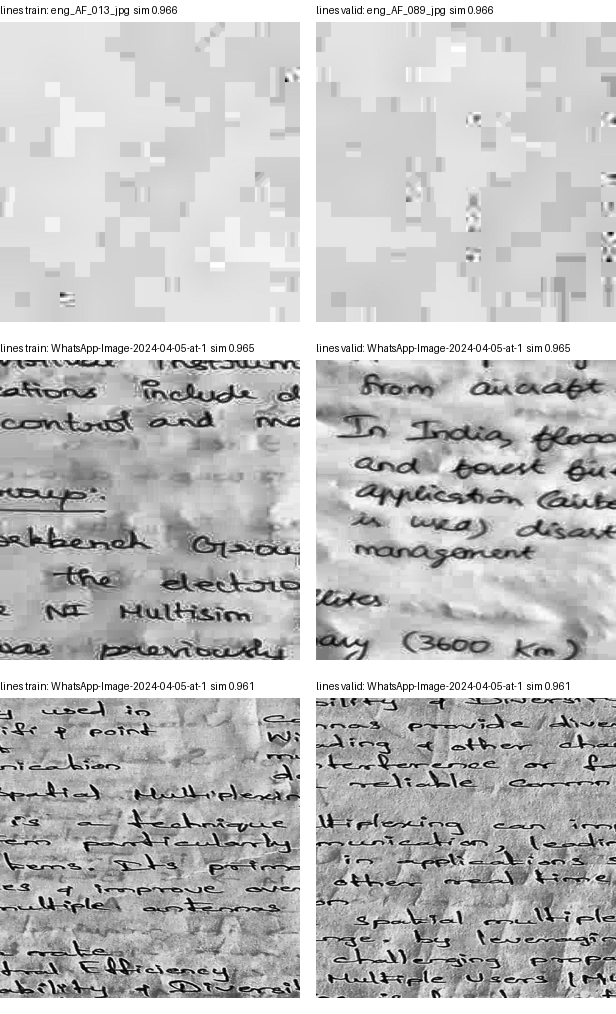

image: closest_cross_split_pairs.png

The WhatsApp session (one writer, one notebook, 23 minutes) in Roboflow's split: {'test': 2, 'train': 15, 'valid': 5}

Answer-sheet pages per booklet (Roboflow puts all of them in train):


group
31-5-2-Science-Topper-Solution           38
30-3-2-Maths-Topper-Solution             34
32-4-2-Social-Science-Topper-Solution    28
32-2_Social-Science-Topper-Solution      23
32-5-1-Social-Science-Topper-Solution    21
31-3-3-Science-Topper-Solution           20
Science_086                              14
Social_Science_087                       14
Name: source, dtype: int64

In [8]:
eda.show(crossing[["dataset", "similarity", "a", "a_split", "b", "b_split", "same_group"]]
         .assign(a=lambda d: d["a"].str[:38], b=lambda d: d["b"].str[:38]), "Closest pairs across Roboflow's splits:")
datasets.contact_sheet(crossing, OUT / "closest_cross_split_pairs.png")
crossing.drop(columns=["a_path", "b_path"]).to_csv(OUT / "closest_cross_split_pairs.csv", index=False)

sessions = index[index["group"] == datasets.WHATSAPP_SESSION].groupby("roboflow_split")["source"].nunique()
print(f"\nThe WhatsApp session (one writer, one notebook, 23 minutes) in Roboflow's split: {sessions.to_dict()}")
booklets = index[index["dataset"] == "answersheet"].groupby("group")["source"].nunique().sort_values(ascending=False)
eda.show(booklets, "Answer-sheet pages per booklet (Roboflow puts all of them in train):")

**What the evidence says.** In both sets, two photos from the same booklet or session are far more alike than
photos from different groups, nearly as alike as two copies of one photo. Roboflow's split of the lines set also
spreads the WhatsApp session (one writer, one notebook) over train, validation and test. So the split is made
by group:

- **Answer sheets:** 8 booklets, split 5/2/1, chosen by subject before looking at any result. Validation keeps two
  (Science and Social Science) because it chooses between grid runs; test keeps one Social Science booklet.
- **Lines:** Roboflow's split, except the WhatsApp session, which all goes to train.

In [9]:
split = datasets.make_split(index)
check = datasets.leakage_after_split(split)
eda.show(split[split["used"]].groupby(["dataset", "our_split"])
         .agg(images=("file", "size"), photos=("source", "nunique"), groups=("group", "nunique"), boxes=("n_boxes", "sum"))
         .reset_index(), "Our split, by group:")
eda.show(check, "Sources and groups found in more than one of train, val and test (must be 0):")
assert check["in_more_than_one_split"].sum() == 0, "a photo or group is in more than one split"
split.drop(columns=["path", "label"]).to_csv(datasets.SPLIT_CSV, index=False)
check.to_csv(OUT / "leakage_after_split.csv", index=False)


Our split, by group:


,dataset,our_split,images,photos,groups,boxes
0,answersheet,test,21,21,1,90
1,answersheet,train,411,137,5,1575
2,answersheet,val,34,34,2,180
3,lines,test,44,11,11,160
4,lines,train,1144,100,79,4016
5,lines,val,92,23,23,304



Sources and groups found in more than one of train, val and test (must be 0):


,dataset,unit,units,in_more_than_one_split
0,answersheet,source,192,0
1,answersheet,group,8,0
2,lines,source,134,0
3,lines,group,113,0


## Part 4. One YOLO dataset per detector

Two detectors, not one with two classes: the answer-sheet pages have lines nobody labelled, and the notebook
photos have question numbers nobody labelled. One combined model would learn that those unlabelled objects are
background. Each detector is trained only on data where its class is fully labelled. After building, a few
images are drawn with their labels back on (the check from the Session 9 notebook), which catches swapped
coordinates, a wrong class map or unconverted polygons before hours of training.

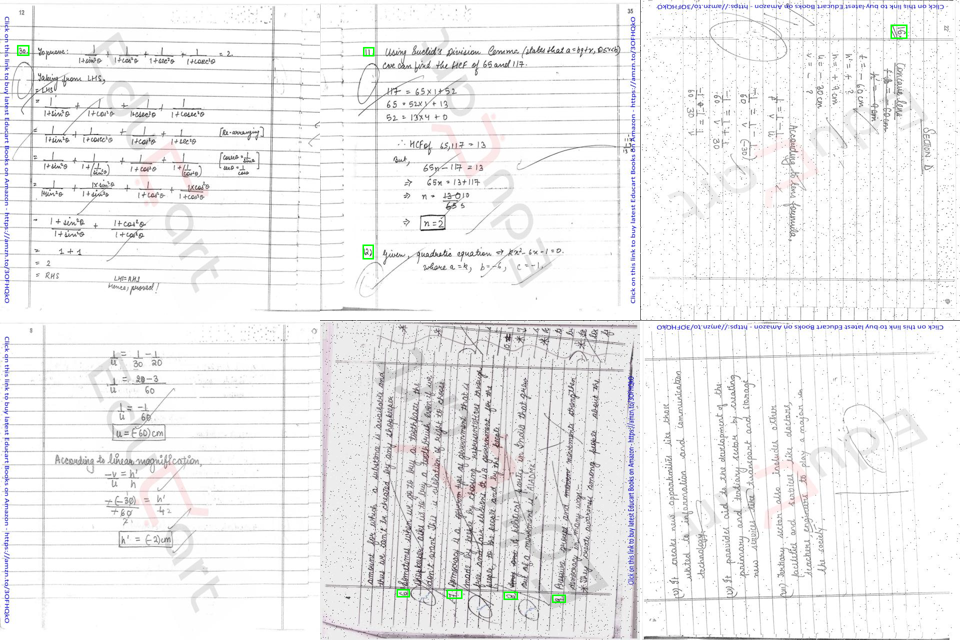

image: labels_question_no.png


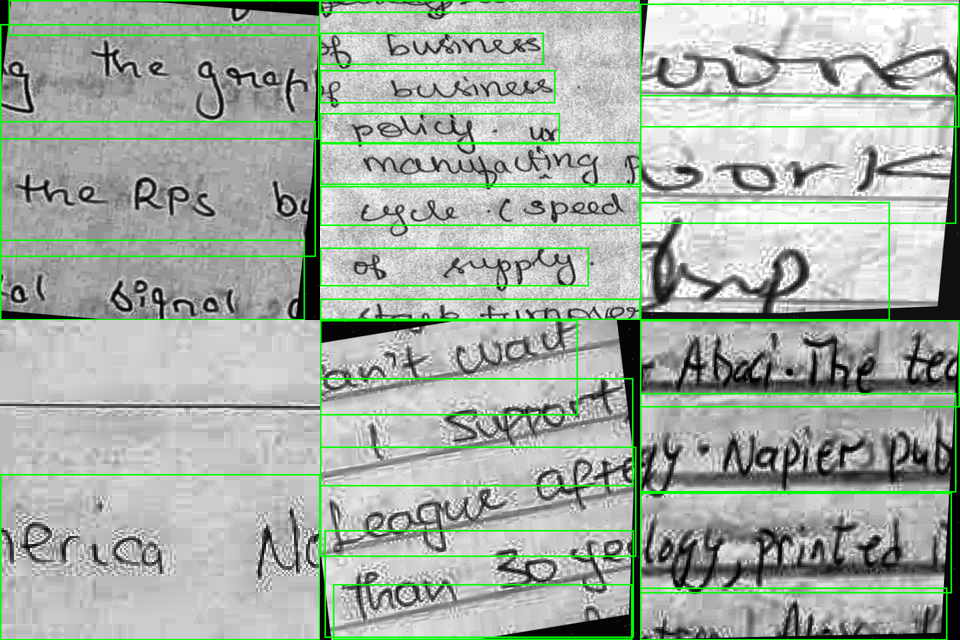

image: labels_text_line.png


In [10]:
DETECTORS = {
    "question_no": dict(dataset="answersheet", class_map={4: 0}),  # class 4 is question_no in the export
    "text_line": dict(dataset="lines", class_map={0: 0}),
}
yamls = {}
for det, spec in DETECTORS.items():
    yamls[det] = datasets.write_yolo(split, spec["dataset"], spec["class_map"], [det], BUILT / det)
    datasets.label_sheet(BUILT / det, OUT / f"labels_{det}.png")

## Part 5. Baselines: is training needed at all?

Two baselines, the same role the trivial baseline had in Assignment 2:

- **Rules, no learning** (`vision/rules.py`): ink bands for lines, and "a narrow word just right of the margin"
  for question numbers. Their few parameters were chosen on validation pages.
- **COCO YOLO11n zero-shot:** a detector that already works, but has no class for either object, so any box counts.

Scores are AP50 over every box (to compare models), and precision and recall at the confidence the reader uses
(to say what the reader will do), as in Session 9: mAP picks a model, the threshold table configures it.

In [11]:
import cv2  # noqa: E402
from ultralytics import YOLO  # noqa: E402

from vision.reader import DETECT_CONF  # noqa: E402
from vision.rules import rule_lines, rule_question_numbers  # noqa: E402


def gt_boxes(label_path: Path, w: int, h: int) -> np.ndarray:
    """A YOLO label file as pixel boxes (x0, y0, x1, y1)."""
    rows = [list(map(float, l.split()[1:5])) for l in label_path.read_text().splitlines() if l.strip()] if label_path.is_file() else []
    out = [[(cx - bw / 2) * w, (cy - bh / 2) * h, (cx + bw / 2) * w, (cy + bh / 2) * h] for cx, cy, bw, bh in rows]
    return np.array(out).reshape(-1, 4)


def iou(box: np.ndarray, boxes: np.ndarray) -> np.ndarray:
    x0 = np.maximum(box[0], boxes[:, 0]); y0 = np.maximum(box[1], boxes[:, 1])
    x1 = np.minimum(box[2], boxes[:, 2]); y1 = np.minimum(box[3], boxes[:, 3])
    inter = np.clip(x1 - x0, 0, None) * np.clip(y1 - y0, 0, None)
    area = lambda b: (b[..., 2] - b[..., 0]) * (b[..., 3] - b[..., 1])  # noqa: E731
    return inter / (area(box) + area(boxes) - inter + 1e-9)


def ap50(predictions: dict, truths: dict) -> dict:
    """All-point AP at IoU 0.5, one class. predictions: image -> [(box, score)], truths: image -> boxes."""
    flat = sorted(((s, img, b) for img, preds in predictions.items() for b, s in preds), key=lambda t: -t[0])
    n_true = sum(len(t) for t in truths.values())
    used = {img: np.zeros(len(t), bool) for img, t in truths.items()}
    tp = np.zeros(len(flat))
    for k, (_, img, box) in enumerate(flat):
        t = truths.get(img, np.zeros((0, 4)))
        if len(t):
            overlaps = iou(np.asarray(box), t)
            j = int(np.argmax(overlaps))
            if overlaps[j] >= 0.5 and not used[img][j]:
                used[img][j] = True
                tp[k] = 1
    if not n_true:
        return dict(ap50=float("nan"), precision=float("nan"), recall=float("nan"))
    cum_tp = np.cumsum(tp)
    recall = cum_tp / n_true
    precision = cum_tp / np.arange(1, len(flat) + 1) if len(flat) else np.array([])
    envelope = np.maximum.accumulate(precision[::-1])[::-1] if len(flat) else np.array([])
    ap = float(np.sum(np.diff(np.concatenate([[0], recall])) * envelope)) if len(flat) else 0.0
    return dict(ap50=ap, precision=float(precision[-1]) if len(flat) else 0.0, recall=float(recall[-1]) if len(flat) else 0.0)


def scores(predictions: dict, truths: dict) -> dict:
    """AP50 over every box, and precision and recall of the boxes the reader keeps (confidence >= DETECT_CONF)."""
    at_conf = {img: [(b, s) for b, s in preds if s >= DETECT_CONF] for img, preds in predictions.items()}
    kept = ap50(at_conf, truths)
    return dict(ap50=ap50(predictions, truths)["ap50"], precision=kept["precision"], recall=kept["recall"])


def split_images(det: str, split: str = "val") -> list[Path]:
    return sorted((BUILT / det / split / "images").iterdir())


def truths_for(det: str, split: str = "val") -> dict:
    from PIL import Image
    out = {}
    for path in split_images(det, split):
        w, h = Image.open(path).size
        out[path.name] = gt_boxes(BUILT / det / split / "labels" / f"{path.stem}.txt", w, h)
    return out


def predict_boxes(model, det: str, split: str) -> dict:
    """Every box a YOLO model finds, down to confidence 0.001, so AP50 sees the whole ranking."""
    preds = {}
    for path in split_images(det, split):
        r = model.predict(str(path), conf=0.001, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
        preds[path.name] = [(b, float(s)) for b, s in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy())]
    return preds


def rule_boxes(det: str, split: str) -> dict:
    rule = rule_question_numbers if det == "question_no" else rule_lines
    return {p.name: [(b, 1.0) for b in rule(cv2.imread(str(p), cv2.IMREAD_GRAYSCALE))] for p in split_images(det, split)}


def cpu_ms_per_image(model, det: str, n: int = 20) -> float:
    """Inference time on the CPU, which is what a free Space has (the training device says nothing about it)."""
    paths = [str(p) for p in split_images(det, "val")[:n]]
    model.predict(paths[0], imgsz=IMGSZ, device="cpu", verbose=False)  # warm-up
    started = time.perf_counter()
    for p in paths:
        model.predict(p, imgsz=IMGSZ, device="cpu", verbose=False)
    return (time.perf_counter() - started) * 1000 / len(paths)

In [12]:
baselines = []
coco = YOLO("yolo11n.pt")
for det in DETECTORS:
    truths = truths_for(det)
    for name, preds in (("rules (no learning)", rule_boxes(det, "val")),
                        ("COCO YOLO11n zero-shot, any box", predict_boxes(coco, det, "val"))):
        baselines.append(dict(detector=det, model=name, **scores(preds, truths)))
baselines = pd.DataFrame(baselines)
eda.show(baselines, f"Baselines on validation (AP50; precision and recall at confidence {DETECT_CONF}):")
baselines.to_csv(RESULTS / "baselines.csv", index=False)


Baselines on validation (AP50; precision and recall at confidence 0.25):


,detector,model,ap50,precision,recall
0,question_no,rules (no learning),0.003,0.011,0.12
1,question_no,"COCO YOLO11n zero-shot, any box",0.000,0.000,0.00
2,text_line,rules (no learning),0.136,0.261,0.51
3,text_line,"COCO YOLO11n zero-shot, any box",0.007,0.000,0.00


**Training is needed.** COCO has no class for question numbers or handwritten lines, so zero-shot only guesses
with unrelated boxes (AP50 about 0). The rules find some lines (AP50 0.14) but almost no question numbers (0.003).

## Part 6. Fine-tuning: a small planned grid, chosen on validation only

What we vary, and why (everything else stays at the Ultralytics defaults):

- **model**, yolo11n vs yolo11s: is the bigger model worth its extra latency on a CPU Space?
- **aug**: `default` flips images left to right, which never happens to writing; `scan` turns that off and adds
  the small rotations, brightness changes and perspective of a phone scan.
- **freeze**, question_no only, around the best so far: freezing 10 backbone layers may generalise better with
  about 140 training pages.
- **lr0**, question_no only, around the best so far: half and double the base rate.

That is 7 runs for question_no and 4 for text_line. Image size is not varied: both exports were resized to
640 x 640 by their authors, so a larger size only upsamples the same pixels.

The optimiser is set explicitly. With Ultralytics' default `optimizer="auto"`, lr0 is *ignored*: for a run this
short it picks AdamW at lr 0.002 by itself, so an lr0 grid would train the same model three times. We fix that
same choice as the base, and the lr0 runs then really move the learning rate.

In [13]:
OPTIMIZER, BASE_LR0, MOMENTUM = "AdamW", 0.002, 0.9
LR0_SWEEP = (0.001, 0.004)
AUGS = {
    "default": dict(),
    "scan": dict(fliplr=0.0, degrees=5.0, hsv_v=0.5, translate=0.05, scale=0.3, perspective=0.0005),
}


def grid_for(det: str) -> list[dict]:
    base = [dict(model=m, aug=a, freeze=0, lr0=BASE_LR0) for m in ("yolo11n", "yolo11s") for a in AUGS]
    return base[:1] if SMOKE else base


def run_name(det: str, cfg: dict) -> str:
    return f"{det}_{cfg['model']}_{cfg['aug']}_f{cfg['freeze']}_lr{cfg['lr0']}"


def train_one(det: str, cfg: dict) -> dict:
    """Train one grid run (unless it already finished and RETRAIN is off), then score it on validation."""
    name = run_name(det, cfg)
    best = RUNS / name / "weights" / "best.pt"
    started = time.time()
    if RETRAIN or SMOKE or not best.is_file():
        # deterministic=False as in the Session 9 notebook: MPS has no deterministic backward for some operations,
        # and seed=0 still fixes the shuffling and the augmentation.
        YOLO(f"{cfg['model']}.pt").train(
            data=str(yamls[det]), epochs=EPOCHS, patience=PATIENCE, imgsz=IMGSZ, batch=16, seed=SEED,
            deterministic=False, freeze=cfg["freeze"] or None, optimizer=OPTIMIZER, lr0=cfg["lr0"],
            momentum=MOMENTUM, project=str(RUNS), name=name, exist_ok=True, plots=False, verbose=False,
            workers=0 if SMOKE else 4, fraction=0.15 if SMOKE else 1.0, device=DEVICE, **AUGS[cfg["aug"]],
        )
    minutes = (time.time() - started) / 60
    model = YOLO(str(best))
    metrics = model.val(data=str(yamls[det]), split="val", imgsz=IMGSZ, device=DEVICE, verbose=False, plots=False)
    ours = scores(predict_boxes(model, det, "val"), truths_for(det))
    epochs_run = len(pd.read_csv(RUNS / name / "results.csv")) if (RUNS / name / "results.csv").is_file() else None
    return dict(detector=det, run=name, **cfg, mAP50_95=float(metrics.box.map), mAP50=float(metrics.box.map50),
                **ours, cpu_ms_per_image=round(cpu_ms_per_image(model, det), 1), epochs_run=epochs_run,
                train_minutes=round(minutes, 1))


results = []
for det in DETECTORS:
    for cfg in grid_for(det):
        print(f"--- {run_name(det, cfg)}")
        results.append(train_one(det, cfg))
    if det == "question_no" and not SMOKE:  # freezing, then learning rate, around the best so far
        best = max((r for r in results if r["detector"] == det), key=lambda r: r["mAP50_95"])
        cfg = dict(model=best["model"], aug=best["aug"], freeze=10, lr0=BASE_LR0)
        print(f"--- {run_name(det, cfg)}")
        results.append(train_one(det, cfg))
        best = max((r for r in results if r["detector"] == det), key=lambda r: r["mAP50_95"])
        for lr in LR0_SWEEP:
            cfg = dict(model=best["model"], aug=best["aug"], freeze=best["freeze"], lr0=lr)
            print(f"--- {run_name(det, cfg)}")
            results.append(train_one(det, cfg))
grid = pd.DataFrame(results).sort_values(["detector", "mAP50_95"], ascending=[True, False])
eda.show(grid.drop(columns=["run"]), "Every grid run on validation, best first:")
grid.to_csv(RESULTS / "grid_results.csv", index=False)

--- question_no_yolo11n_default_f0_lr0.002


--- question_no_yolo11n_scan_f0_lr0.002


--- question_no_yolo11s_default_f0_lr0.002


--- question_no_yolo11s_scan_f0_lr0.002


--- question_no_yolo11n_scan_f10_lr0.002


--- question_no_yolo11n_scan_f0_lr0.001


... (3 outputs left out)

--- text_line_yolo11s_default_f0_lr0.002


--- text_line_yolo11s_scan_f0_lr0.002



Every grid run on validation, best first:


,detector,model,aug,freeze,lr0,mAP50_95,mAP50,ap50,precision,recall,cpu_ms_per_image,epochs_run,train_minutes
1,question_no,yolo11n,scan,0,0.002,0.229,0.490,0.506,0.494,0.573,24.2,34,0.0
5,question_no,yolo11n,scan,0,0.001,0.219,0.532,0.532,0.633,0.507,28.0,34,0.0
6,question_no,yolo11n,scan,0,0.004,0.195,0.455,0.482,0.645,0.533,26.7,40,0.0
4,question_no,yolo11n,scan,10,0.002,0.181,0.487,0.492,0.597,0.493,24.9,30,0.0
0,question_no,yolo11n,default,0,0.002,0.167,0.425,0.442,0.625,0.267,26.4,26,0.0
2,question_no,yolo11s,default,0,0.002,0.166,0.361,0.355,0.482,0.360,46.3,32,0.0
3,question_no,yolo11s,scan,0,0.002,0.142,0.363,0.352,0.220,0.507,44.2,17,0.0
7,text_line,yolo11n,default,0,0.002,0.495,0.878,0.889,0.848,0.862,24.6,30,0.0
9,text_line,yolo11s,default,0,0.002,0.482,0.867,0.876,0.831,0.875,45.2,24,0.0
8,text_line,yolo11n,scan,0,0.002,0.478,0.892,0.901,0.908,0.842,24.9,40,0.0


**What the grid says.** For question numbers, the small model with scan augmentation wins (mAP50-95 0.23); the
bigger model, freezing and other learning rates are all worse, and the bigger model is also twice as slow on a
CPU. For lines, the four runs are within 0.02 of each other and the small default model is chosen. Question
numbers stay hard: even the best run finds about 57% of them on validation at the reader's threshold.

## Part 7. Save the chosen models, and the confidence threshold

The chosen run per detector is the one with the best mAP50-95 on validation. Its weights are copied to
`weights/` only if they differ from what is there: the reader keys its cache on the weight files, so copying an
identical file again would make every later step re-read its exams for nothing.

In [14]:
chosen = {}
for det, part in grid.groupby("detector"):
    top = part.iloc[0]
    target = WEIGHTS / f"{det}_detector.pt"
    source = RUNS / top["run"] / "weights" / "best.pt"
    if not target.is_file() or target.read_bytes() != source.read_bytes():
        shutil.copy2(source, target)
    rules_ap = baselines[(baselines["detector"] == det) & baselines["model"].str.startswith("rules")]["ap50"].iloc[0]
    chosen[det] = dict(run=top["run"], weights=str(target.relative_to(ROOT)) if not SMOKE else str(target),
                       mAP50_95=float(top["mAP50_95"]), mAP50=float(top["mAP50"]), ap50_minus_rules=float(top["ap50"] - rules_ap),
                       reader_conf=DETECT_CONF, cpu_ms_per_image=float(top["cpu_ms_per_image"]))
    print(f"{det:12s} {top['run']}  mAP50-95 {top['mAP50_95']:.3f}  mAP50 {top['mAP50']:.3f}  -> {target.name}")
(RESULTS / "chosen.json").write_text(json.dumps(dict(smoke=SMOKE, chosen=chosen), indent=2))

question_no  question_no_yolo11n_scan_f0_lr0.002  mAP50-95 0.229  mAP50 0.490  -> question_no_detector.pt
text_line    text_line_yolo11n_default_f0_lr0.002  mAP50-95 0.495  mAP50 0.878  -> text_line_detector.pt


655

In [15]:
# The threshold is a dial (Session 9, 6.3). For question numbers a miss is the worse error: its answer is merged
# into the previous question. The sweep lets the reader's threshold be revisited on validation, never on test.
sweep = []
for det in DETECTORS:
    preds, truths = predict_boxes(YOLO(str(WEIGHTS / f"{det}_detector.pt")), det, "val"), truths_for(det)
    for cut in (0.05, 0.1, 0.15, 0.25, 0.4, 0.5, 0.6, 0.75):
        kept = ap50({img: [(b, s) for b, s in p if s >= cut] for img, p in preds.items()}, truths)
        sweep.append(dict(detector=det, conf=cut, precision=kept["precision"], recall=kept["recall"]))
sweep = pd.DataFrame(sweep)
eda.show(sweep.pivot(index="conf", columns="detector", values=["precision", "recall"]),
         f"Chosen models on validation, by confidence threshold (the reader uses {DETECT_CONF}):")
sweep.to_csv(RESULTS / "conf_sweep_val.csv", index=False)


Chosen models on validation, by confidence threshold (the reader uses 0.25):


precision                recall          
detector question_no text_line question_no text_line
conf                                                
0.05           0.349     0.461       0.680     0.918
0.10           0.403     0.615       0.667     0.908
0.15           0.438     0.738       0.653     0.882
0.25           0.494     0.848       0.573     0.862
0.40           0.563     0.927       0.533     0.793
0.50           0.571     0.957       0.480     0.655
0.60           0.647     0.969       0.440     0.405
0.75           0.792     1.000       0.253     0.046

## Part 8. Test, once

The chosen models and the baselines on the test split, which nothing above looked at. Nothing is chosen here.

In [16]:
rows = []
for det in DETECTORS:
    truths = truths_for(det, "test")
    model = YOLO(str(WEIGHTS / f"{det}_detector.pt"))
    metrics = model.val(data=str(yamls[det]), split="test", imgsz=IMGSZ, device=DEVICE, verbose=False, plots=False)
    for name, preds in (("finetuned (chosen on val)", predict_boxes(model, det, "test")),
                        ("rules (no learning)", rule_boxes(det, "test")),
                        ("COCO YOLO11n zero-shot, any box", predict_boxes(coco, det, "test"))):
        rows.append(dict(detector=det, model=name, images=len(truths), **scores(preds, truths)))
    rows[-3].update(mAP50_95=float(metrics.box.map), mAP50=float(metrics.box.map50))
test = pd.DataFrame(rows)
eda.show(test, f"Test split (AP50; precision and recall at confidence {DETECT_CONF}):")
test.to_csv(RESULTS / "test_results.csv", index=False)


Test split (AP50; precision and recall at confidence 0.25):


,detector,model,images,ap50,precision,recall,mAP50_95,mAP50
0,question_no,finetuned (chosen on val),21,0.795,0.651,0.778,0.398,0.795
1,question_no,rules (no learning),21,0.000,0.000,0.000,NaN,NaN
2,question_no,"COCO YOLO11n zero-shot, any box",21,0.000,0.000,0.000,NaN,NaN
3,text_line,finetuned (chosen on val),44,0.882,0.804,0.844,0.449,0.863
4,text_line,rules (no learning),44,0.190,0.247,0.569,NaN,NaN
5,text_line,"COCO YOLO11n zero-shot, any box",44,0.001,0.000,0.000,NaN,NaN


## Conclusion, and why it leads to step 2

**Training works on its own data.** On the unseen test booklet and notebooks, the fine-tuned detectors reach
AP50 0.79 for question numbers and 0.88 for lines, where the rules reach 0.00 and 0.19 and COCO zero-shot
nothing. The split by group means these numbers are not inflated by copies of training pages.

**But a good test score only says the detector finds these labels on these booklets.** The question-number
detector learnt from 5 booklets, all from one source (the "Topper Solution" answer booklets, with "13)"-style
numbers on ruled answer sheets). Whether it finds the numbers on other exams is the real question, and the only
way to know is to read real exams with it. Step 2 does that once, with the whole reader.